In [306]:
import numpy as np
import matplotlib.pyplot as plt
import h5py

from src.FunctionsGenerator import FunctionsGenerator
from src.Heat1DCrankNicolson import Heat1DCrankNicolson
from src.print_utils import print_kv, print_section

plt.style.use("styles/plots.mplstyle")
np.random.seed(42)

In [307]:
dataset_code    = "lru5_20/"

# --- Load simulation parameters --------

L, Tf, nt, D, h_param, l, _, r, _ = np.loadtxt(
    f"dataset/{dataset_code}simulation_info.csv", delimiter=";", usecols=1
)
nt = int(nt)
dt = Tf / nt
n  = int(2 * nt - 1)

# --- Load impulse response --------------

h_vals = np.loadtxt( f"dataset/{dataset_code}impulse_response.csv", delimiter=";")
H_np   = np.fft.rfft(h_vals, n).astype(np.complex64)
nk     = len(H_np)
freqs  = np.fft.rfftfreq(n, d=dt)
omegas = freqs * 2 * np.pi

# ---- Load dataset ----------------------

VAL_FRACTION = 0.1
SEED         = 42
H5_PATH      =  f"dataset/{dataset_code}dataset.h5"

with h5py.File(H5_PATH, "r") as hf:
    data = hf["dataset"][:]              # (N, 2, nt)

f_all = data[:, 0, :].astype(np.float32)
g_all = data[:, 1, :].astype(np.float32)

In [308]:
# ---- Apply delay ------------------------

rolling = 0 # Simulate a delay of: tau = rolling * dt

if rolling != 0:
    g_rolled = np.roll(g_all, rolling,axis=1)
    g_rolled[:,:rolling] = 0
    g_all = g_rolled
    
    print_kv("Rolling applied", rf"{rolling} elements, $\Delta_t$ = {rolling*dt}")

In [309]:
# ---- Apply noise -------------------------

from math import pi


noise_level = 0.05 # e.g. 0.05 = 5% of noise over the signal strenght

if noise_level > 0:
    sample_std = np.std(g_all, axis=1, keepdims=True)

    noise = np.random.normal(
        0.0,
        noise_level * sample_std,
        size=g_all.shape
    ).astype(np.float32)

    g_all += noise

    print_kv("Gaussian noise applied", f"{noise_level*100}%")

Gaussian noise applied                                            5.0%


In [310]:
f_trap = f_all.copy()
f_trap[:, :-1] = (f_all[:, :-1] + f_all[:, 1:]) / 2.0
f_trap[:,  -1] = f_all[:, -1] / 2.0

F_all = np.fft.rfft(f_trap, n=n, axis=1)

g_trap = g_all.copy()
g_trap[:, :-1] = (g_all[:, :-1] + g_all[:, 1:]) / 2.0
g_trap[:,  -1] = g_all[:, -1] / 2.0

G_all      = np.fft.rfft(g_trap, n=n, axis=1)        # (N, nk)

print(np.shape(G_all))

(800, 2000)


In [311]:
# --- Validation and trainign set declaration --------

N = len(f_all)

rng       = np.random.default_rng(SEED)
idx       = rng.permutation(N)
n_val     = max(1, int(VAL_FRACTION * N))
idx_val   = idx[:n_val]
idx_train = idx[n_val:]

print_kv("Dataset", f"total={N}, train={len(idx_train)}, val={n_val}")

G_train = G_all[idx_train]
F_train = F_all[idx_train]
G_val   = G_all[idx_val]
F_val   = F_all[idx_val]

Dataset                                      total=800, train=720, val=80


In [312]:
G_power_spectrum = np.mean(G_train*np.conj(G_train), axis=0)
corr =  np.mean(G_train*np.conj(F_train), axis=0)

Hc = corr*np.conj(H_np)
H_mod_2 = np.conj(H_np)*H_np

alpha_k = np.angle(np.conj(H_np) * corr)
R_star  = (np.abs(H_np)**2 * G_power_spectrum) / np.abs(np.conj(H_np)*corr) - np.abs(H_np)**2
phi_star = -alpha_k

F_opt = (np.conj(corr) / G_power_spectrum) * G_val

f_opt = np.fft.irfft(F_opt, n=n, axis=1)[:, :nt]
f_val = np.fft.irfft(F_val, n=n, axis=1)[:, :nt]
g_val = np.fft.irfft(G_val, n=n, axis=1)[:, :nt]

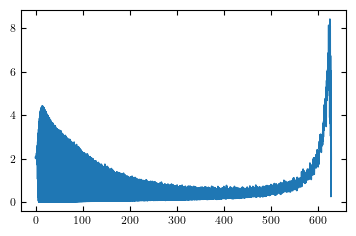

In [313]:
plt.plot(omegas,np.abs(np.conj(corr) / G_power_spectrum))

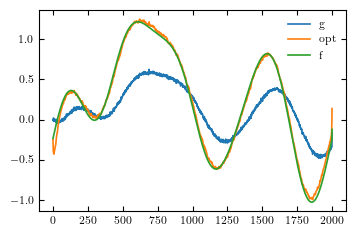

In [314]:
plt.plot(g_val[8], label="g")
plt.plot(f_opt[8], label="opt")
plt.plot(f_val[8], label="f")
plt.legend()

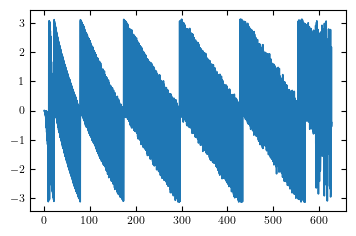

In [315]:
plt.plot(omegas,phi_star)

/home/simone/anaconda3/envs/thesis_env/lib/python3.10/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/simone/anaconda3/envs/thesis_env/lib/python3.10/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


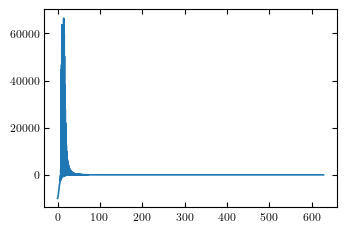

In [316]:
plt.plot(omegas,R_star)